# Praktikum 2 - Pencarian Similarity Menggunakan FAISS Flat Index

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 06:** ANN (Approximate Nearest Neighbors)

### Tujuan Praktikum:
1. Memahami library **FAISS (Facebook AI Similarity Search)** yang dirancang untuk pencarian vektor berskala masif.
2. Membangun indeks L2 dasar (`faiss.IndexFlatL2`).
3. Mengukur kecepatan pencarian dan memvisualisasikan hasil tetangga terdekat.

## Langkah 1 - Import FAISS dan Pembuatan Vektor

In [1]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

np.random.seed(42)
n_samples = 1000
dim = 2
X = np.random.rand(n_samples, dim).astype('float32')
query = np.random.rand(1, dim).astype('float32')
k = 3

## Langkah 2 - Membangun IndexFlatL2 dan Pencarian k-NN

In [2]:
start = time.time()
index = faiss.IndexFlatL2(dim)
index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = index.search(query, k)
search_time = time.time() - start

print(f'Total vektor di index: {index.ntotal}')
print(f'Waktu build index : {build_time*1000:.3f} ms')
print(f'Waktu search query: {search_time*1000:.3f} ms')
print(f'Indeks tetangga terdekat: {indices[0]}')
print(f'Jarak kuadrat (L2 squared): {distances[0]}')

Total vektor di index: 1000
Waktu build index : 1.837 ms
Waktu search query: 1.553 ms
Indeks tetangga terdekat: [112 535 777]
Jarak kuadrat (L2 squared): [2.1161813e-05 1.3761134e-03 2.3510854e-03]


## Langkah 3 - Visualisasi Hasil FAISS Flat

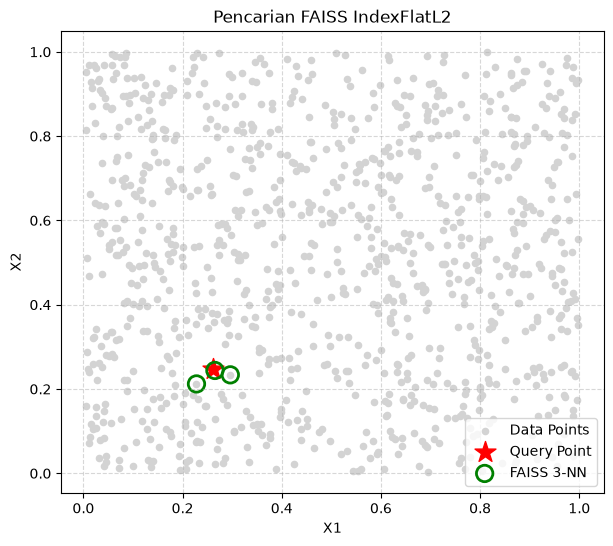

In [3]:
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c='lightgray', s=20, label='Data Points')
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=250, label='Query Point')
plt.scatter(X[indices[0], 0], X[indices[0], 1], facecolors='none', edgecolors='green', s=140, linewidth=2, label='FAISS 3-NN')
plt.title('Pencarian FAISS IndexFlatL2')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()